# 02. Базовые модели и проверка асимметрии

Вариант 6. Выполняйте блокноты в порядке 01 → 02 → 03 → 04. Код этапа взят из scripts.

Период данных: 2016–2025; отличие от требуемого 2010–2025 необходимо согласовать с преподавателем.

In [1]:
from pathlib import Path
import subprocess
import sys
import os

project = Path("/content/fintech_nbk_corrected")

if not (project / ".git").exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/BEJLIKAN/fintech-nbk-rates.git",
            str(project)
        ],
        check=True
    )

os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import numpy as np
import pandas as pd
import scipy
import statsmodels.api as sm
import sklearn
import matplotlib.pyplot as plt

%matplotlib inline

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Statsmodels:", sm.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Среда готова — можно запускать вторую ячейку.")


NumPy: 2.1.3
Pandas: 2.2.3
SciPy: 1.16.3
Statsmodels: 0.15.0
Scikit-learn: 1.6.1
Среда готова — можно запускать вторую ячейку.


Библиотеки подключены
Загруженные CSV:
NBK_BNS_variant6_2016_2025.csv

Нужный файл найден
Строк: 120
Столбцов: 8
Данные проверены: 120 месяцев без пропусков и повторов
Обучение: май 2016 — ноябрь 2022 после создания лагов
Validation для подбора: январь 2023 — май 2024
Декабрь 2022 и июнь 2024 исключены как временные зазоры
Test: июль 2024 — декабрь 2025; пока не используем
Прогнозируем изменение ставки в месяце t.
Признаки используем не позднее t−2.
Это предварительное допущение о сроках публикации.


,Признак,Экономический смысл
0,inflation_yoy_lag2,Прошлый уровень годовой инфляции
1,inflation_mom_lag2,Прошлый месячный рост цен
2,inflation_change_lag2,Прошлое ускорение или замедление годовой инфляции
3,inflation_up_lag2,Положительная часть изменения годовой инфляции
4,inflation_down_lag2,Отрицательная часть изменения годовой инфляции
5,base_rate_lag2,Прошлый уровень базовой ставки
6,base_change_lag2,Прошлое изменение базовой ставки
7,inflation_mean3_lag2,Средняя годовая инфляция за 3 прошлых месяца
8,inflation_std3_lag2,Изменчивость годовой инфляции за 3 прошлых месяца
9,real_base_proxy_lag2,Базовая ставка минус годовая инфляция; приближ...


Юридические лица | Train: 79 | Validation: 17 | Признаков: 16
Физические лица, включая ИП | Train: 79 | Validation: 17 | Признаков: 16
Проверка пройдена: будущие строки не влияют на прошлые признаки
Симметричная модель:
['loan_change_lag2', 'base_change_lag2', 'inflation_change_lag2']

Асимметричная модель:
['loan_change_lag2', 'base_change_lag2', 'inflation_up_lag2', 'inflation_down_lag2']
Обучены 4 регрессии: по 2 для каждой группы


,Группа,Модель,"RMSE, п.п.","MAE, п.п.",R²
0,Юридические лица,zero_change,0.3681,0.2949,-0.0307
1,Юридические лица,symmetric,0.4269,0.3247,-0.3864
2,Юридические лица,asymmetric,0.4130,0.3159,-0.2978
3,"Физические лица, включая ИП",zero_change,1.6737,1.2036,-0.0116
4,"Физические лица, включая ИП",symmetric,1.7122,1.3397,-0.0586
5,"Физические лица, включая ИП",asymmetric,1.7140,1.3550,-0.0608


,Группа,Коэффициент при росте,Коэффициент при снижении,Wald p-value,Вывод при уровне 5%
0,Юридические лица,0.1827,0.0628,0.6318,Недостаточно оснований отвергнуть равенство
1,"Физические лица, включая ИП",-0.2562,0.0746,0.1305,Недостаточно оснований отвергнуть равенство


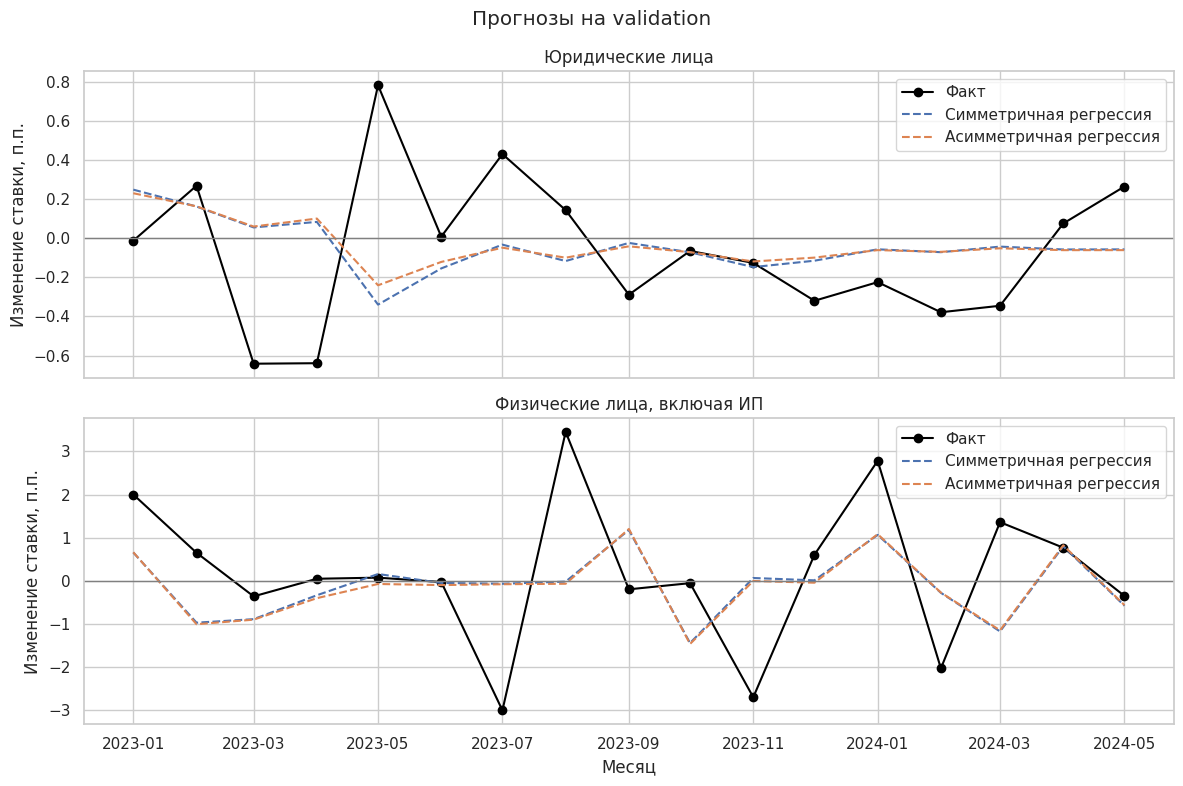

In [2]:
from src.train import fit_baseline
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    raise RuntimeError("Сначала скачайте весь репозиторий и перейдите в его папку")
sys.path.insert(0, str(ROOT))
WORK = ROOT / "results/reproduced"
WORK.mkdir(parents=True, exist_ok=True)


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from pathlib import Path
from IPython.display import display
from src.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

print("Библиотеки подключены")

data_path = (ROOT / "data/NBK_BNS_variant6_2016_2025.csv")

print("Загруженные CSV:")
for file in (ROOT / "data").glob("*.csv"):
    print(file.name)

assert data_path.exists(), "Загрузите CSV с исходным названием."

print("\nНужный файл найден")

data = pd.read_csv(data_path, encoding="utf-8-sig")

data["month"] = pd.to_datetime(
    data["month"], format="%Y-%m", errors="raise"
)

data = data.sort_values("month").reset_index(drop=True)

print("Строк:", len(data))
print("Столбцов:", len(data.columns))

required = [
    "month",
    "loan_business_pct",
    "loan_households_pct",
    "inflation_mom_pct",
    "inflation_yoy_pct",
    "base_rate_pct",
    "Y_business_change_pp",
    "Y_households_change_pp",
]

assert set(data.columns) == set(required)

numeric_columns = required[1:]
data[numeric_columns] = data[numeric_columns].apply(
    pd.to_numeric, errors="raise"
)

assert np.isfinite(data[numeric_columns].to_numpy()).all()
assert pd.DatetimeIndex(data["month"]).equals(
    pd.date_range("2016-01-01", "2025-12-01", freq="MS")
)

print("Данные проверены: 120 месяцев без пропусков и повторов")

TRAIN_END = pd.Timestamp("2022-12-01")
VALID_END = pd.Timestamp("2024-06-01")

development = data[data["month"] <= VALID_END].copy()
test_locked = data[data["month"] > VALID_END].copy()

assert (development["month"] <= TRAIN_END).sum() == 84
assert (development["month"] > TRAIN_END).sum() == 18
assert len(test_locked) == 18

print("Обучение: май 2016 — ноябрь 2022 после создания лагов")
print("Validation для подбора: январь 2023 — май 2024")
print("Декабрь 2022 и июнь 2024 исключены как временные зазоры")
print("Test: июль 2024 — декабрь 2025; пока не используем")

FEATURE_LAG = 2

targets = {
    "business": "Y_business_change_pp",
    "households": "Y_households_change_pp",
}

group_names = {
    "business": "Юридические лица",
    "households": "Физические лица, включая ИП",
}

print("Прогнозируем изменение ставки в месяце t.")
print("Признаки используем не позднее t−2.")
print("Это предварительное допущение о сроках публикации.")

from src.features import make_macro_features

from src.features import make_features

feature_meanings = {
    "inflation_yoy_lag2": "Прошлый уровень годовой инфляции",
    "inflation_mom_lag2": "Прошлый месячный рост цен",
    "inflation_change_lag2": "Прошлое ускорение или замедление годовой инфляции",
    "inflation_up_lag2": "Положительная часть изменения годовой инфляции",
    "inflation_down_lag2": "Отрицательная часть изменения годовой инфляции",
    "base_rate_lag2": "Прошлый уровень базовой ставки",
    "base_change_lag2": "Прошлое изменение базовой ставки",
    "inflation_mean3_lag2": "Средняя годовая инфляция за 3 прошлых месяца",
    "inflation_std3_lag2": "Изменчивость годовой инфляции за 3 прошлых месяца",
    "real_base_proxy_lag2": "Базовая ставка минус годовая инфляция; приближение",
    "loan_rate_lag2": "Прошлый уровень кредитной ставки",
    "loan_change_lag2": "Изменение кредитной ставки двумя месяцами ранее",
    "loan_change_lag3": "Изменение кредитной ставки тремя месяцами ранее",
    "loan_change_mean3_lag2": "Среднее изменение ставки за 3 прошлых месяца",
    "loan_change_std3_lag2": "Изменчивость изменений ставки за 3 прошлых месяца",
    "loan_base_spread_lag2": "Прошлая разница кредитной и базовой ставок",
}

display(pd.DataFrame(
    feature_meanings.items(),
    columns=["Признак", "Экономический смысл"]
))

datasets = {}

for group, target in targets.items():
    X = make_features(development, group, FEATURE_LAG)

    usable = X.notna().all(axis=1)

    train_mask = (
        usable
        & (development["month"] <= pd.Timestamp("2022-11-01"))
    )

    valid_mask = (
        usable
        & (development["month"] > TRAIN_END)
        & (development["month"] <= pd.Timestamp("2024-05-01"))
    )

    assert train_mask.sum() == 79
    assert valid_mask.sum() == 17

    datasets[group] = {
        "X_train": X.loc[train_mask].copy(),
        "y_train": development.loc[train_mask, target].copy(),
        "X_valid": X.loc[valid_mask].copy(),
        "y_valid": development.loc[valid_mask, target].copy(),
        "dates_valid": development.loc[valid_mask, "month"].copy(),
    }

    print(
        group_names[group],
        "| Train:", train_mask.sum(),
        "| Validation:", valid_mask.sum(),
        "| Признаков:", X.shape[1]
    )

cut = 60

for group in targets:
    full_features = make_features(
        development, group, FEATURE_LAG
    )

    past_features = make_features(
        development.iloc[:cut].copy(), group, FEATURE_LAG
    )

    pd.testing.assert_frame_equal(
        full_features.iloc[:cut].reset_index(drop=True),
        past_features.reset_index(drop=True)
    )

print("Проверка пройдена: будущие строки не влияют на прошлые признаки")

symmetric_columns = [
    "loan_change_lag2",
    "base_change_lag2",
    "inflation_change_lag2",
]

asymmetric_columns = [
    "loan_change_lag2",
    "base_change_lag2",
    "inflation_up_lag2",
    "inflation_down_lag2",
]

print("Симметричная модель:")
print(symmetric_columns)

print("\nАсимметричная модель:")
print(asymmetric_columns)

baseline_models = {}

for group, parts in datasets.items():
    baseline_models[group] = {}

    for name, columns in [
        ("symmetric", symmetric_columns),
        ("asymmetric", asymmetric_columns),
    ]:
        X_train = sm.add_constant(
            parts["X_train"][columns],
            has_constant="add"
        )

        assert np.linalg.matrix_rank(X_train.to_numpy()) == X_train.shape[1]

        model = fit_baseline(parts['y_train'], X_train)

        baseline_models[group][name] = model

print("Обучены 4 регрессии: по 2 для каждой группы")

validation_rows = []
validation_predictions = {}

for group, parts in datasets.items():
    validation_predictions[group] = {
        "zero_change": np.zeros(len(parts["y_valid"]))
    }

    for name, columns in [
        ("symmetric", symmetric_columns),
        ("asymmetric", asymmetric_columns),
    ]:
        X_valid = sm.add_constant(
            parts["X_valid"][columns],
            has_constant="add"
        )

        validation_predictions[group][name] = (
            baseline_models[group][name].predict(X_valid)
        )

    for name, prediction in validation_predictions[group].items():
        validation_rows.append({
            "Группа": group_names[group],
            "Модель": name,
            "RMSE, п.п.": np.sqrt(
                mean_squared_error(parts["y_valid"], prediction)
            ),
            "MAE, п.п.": mean_absolute_error(
                parts["y_valid"], prediction
            ),
            "R²": r2_score(parts["y_valid"], prediction),
        })

validation_results = pd.DataFrame(validation_rows)

display(validation_results.round(4))

wald_rows = []

for group in targets:
    model = baseline_models[group]["asymmetric"]

    result = model.wald_test(
        "inflation_up_lag2 = inflation_down_lag2",
        use_f=False,
        scalar=True
    )

    p_value = float(result.pvalue)

    wald_rows.append({
        "Группа": group_names[group],
        "Коэффициент при росте": model.params["inflation_up_lag2"],
        "Коэффициент при снижении": model.params["inflation_down_lag2"],
        "Wald p-value": p_value,
        "Вывод при уровне 5%": (
            "Равенство коэффициентов отвергается"
            if p_value < 0.05
            else "Недостаточно оснований отвергнуть равенство"
        ),
    })

wald_results = pd.DataFrame(wald_rows)

display(wald_results.round(4))

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for ax, group in zip(axes, targets):
    parts = datasets[group]

    ax.plot(
        parts["dates_valid"], parts["y_valid"],
        label="Факт", color="black", marker="o"
    )

    for name, label in [
        ("symmetric", "Симметричная регрессия"),
        ("asymmetric", "Асимметричная регрессия"),
    ]:
        ax.plot(
            parts["dates_valid"],
            validation_predictions[group][name],
            label=label,
            linestyle="--"
        )

    ax.axhline(0, color="gray", linewidth=1)
    ax.set_title(group_names[group])
    ax.set_ylabel("Изменение ставки, п.п.")
    ax.legend()

axes[1].set_xlabel("Месяц")
fig.suptitle("Прогнозы на validation")

plt.tight_layout()
plt.show()
